# 🍔 Yelp Scraping — Avis clients McDonald's en France

**Objectif :** récupérer automatiquement les avis Yelp de restaurants McDonald's dans 9 grandes villes françaises, les stocker proprement, puis les analyser pour répondre à trois questions :

1. **Où** les clients sont-ils le plus / le moins satisfaits ?
2. **De quoi** se plaignent-ils (service, plats, livraison) ?
3. **Comment** la satisfaction évolue-t-elle dans le temps ?

**Plan du notebook**

| Étape | Contenu |
|---|---|
| 1. Collecte | Scraping Yelp avec Selenium (liste des restaurants puis avis) |
| 2. Stockage | Sauvegarde dans une base SQLite + export CSV |
| 3. Qualité des données | Doublons, valeurs manquantes, statistiques descriptives |
| 4. Analyse | Notes, analyse de sentiment, thèmes, nuages de mots, évolution |
| 5. Conclusion | Ce qu'il faut retenir et limites |

> ⚠️ Les étapes 1 et 2 nécessitent Google Chrome et une connexion Internet. Pour reproduire uniquement l'analyse, commencez directement à l'**étape 3** : les données sont déjà fournies dans `data/`.

## 1. Collecte des données (scraping)

### 1.1 Configuration
On importe les librairies, on définit les villes ciblées et on ouvre un navigateur Chrome piloté par **Selenium** (Yelp charge son contenu en JavaScript : une simple requête HTTP ne suffit pas).

In [2]:
from selenium import webdriver
from selenium.webdriver.common.by import By
import pandas as pd
import time        # pauses entre les pages (laisser le temps à la page de charger)
import re          # expressions régulières (repérer "McDonald", une date, un code postal…)
import dateparser  # convertit "16 déc. 2023" en date exploitable

# Les 9 villes dans lesquelles on cherche des McDonald's
villes = ["Lille", "Montpellier", "Strasbourg", "Paris",
          "Marseille", "Lyon", "Rouen", "Nice", "Bordeaux"]

# Ouverture d'un navigateur Chrome contrôlé par Python
driver = webdriver.Chrome()
driver.maximize_window()
driver.get("https://www.yelp.fr/search?find_desc=macdo&find_loc=Paris")

### 1.2 Récupérer la liste des restaurants
Pour chaque ville, on lance une recherche « macdo » sur Yelp et on garde uniquement les liens dont le nom commence par *McDonald* / *Mc Donald*.
Les liens sont stockés dans un dictionnaire `{url: ville}`, ce qui évite automatiquement les doublons.

In [3]:
liens_mcdo = {}  # {url du restaurant : ville de recherche}

for ville in villes:
    driver.get("https://www.yelp.fr/search?find_desc=macdo&find_loc=" + ville)
    time.sleep(4)  # on attend que les résultats s'affichent

    nb_ville = 0
    # Tous les liens qui pointent vers une fiche restaurant ("/biz/...")
    for lien in driver.find_elements(By.XPATH, "//a[contains(@href,'/biz/')]"):
        nom = lien.text.strip().lower()
        # On ne garde que les McDonald's (accepte "mcdonald" et "mc donald")
        if re.match(r"mc ?donald", nom):
            url = lien.get_attribute("href").split("?")[0]  # on retire les paramètres de suivi
            if url not in liens_mcdo:
                liens_mcdo[url] = ville
                nb_ville += 1

    print(ville, ":", nb_ville, "McDonald's trouvés")

print("Total :", len(liens_mcdo), "restaurants McDonald's")

Lille : 3 McDonald's trouvés
Montpellier : 4 McDonald's trouvés
Strasbourg : 2 McDonald's trouvés
Paris : 10 McDonald's trouvés
Marseille : 6 McDonald's trouvés
Lyon : 5 McDonald's trouvés
Rouen : 5 McDonald's trouvés
Nice : 7 McDonald's trouvés
Bordeaux : 3 McDonald's trouvés
Total : 45 restaurants McDonald's


✅ **45 restaurants** trouvés. Paris en fournit le plus (10), Strasbourg le moins (2).

> ℹ️ Yelp élargit parfois la recherche aux communes voisines : la « ville » correspond donc à la **zone de recherche**, pas forcément à la commune exacte (ex. un McDonald's de Villeneuve-d'Ascq rattaché à Lille).

### 1.3 Récupérer les avis de chaque restaurant
Pour chaque fiche restaurant :
1. on lit l'**adresse** (le paragraphe qui contient un code postal à 5 chiffres) ;
2. on déplie les avis tronqués (« Lire la suite ») ;
3. pour chaque avis, on extrait la **note** (nombre d'étoiles), la **date** et le **texte** ;
4. on passe à la page suivante tant qu'il y en a une.

Un restaurant **sans aucun avis** est quand même enregistré (avec note/date/texte vides) pour garder une trace de son existence.

In [4]:
avis_data = []  # une ligne = un avis

for url, ville in liens_mcdo.items():
    print(ville, ":", url)
    driver.get(url)
    time.sleep(4)

    # --- Adresse : le paragraphe en gras qui contient un code postal ---
    adresse = None
    for p in driver.find_elements(By.XPATH, "//p[@data-font-weight='semibold']"):
        if re.search(r"\d{5}", p.text):
            adresse = p.text.strip()

    nb_avis_resto = 0

    # --- Parcours de toutes les pages d'avis ---
    while True:
        # Déplier les avis longs pour récupérer le texte complet
        for bouton in driver.find_elements(By.XPATH, "//button[contains(., 'Lire la suite')]"):
            try:
                bouton.click()
            except:
                pass  # bouton non cliquable : on ignore

        avis_page = driver.find_elements(By.XPATH, "//li[.//p[contains(@class,'comment__')]]")

        for avis in avis_page:
            # Note : lue dans l'attribut aria-label, ex. "Note de 4 étoiles"
            note = None
            for etoiles in avis.find_elements(By.XPATH, ".//*[@role='img']"):
                label = str(etoiles.get_attribute("aria-label"))
                if "étoile" in label:
                    note = int(re.search(r"\d+", label).group())

            # Date : un <span> du type "16 déc. 2023", convertie au format AAAA-MM-JJ
            date = None
            for span in avis.find_elements(By.TAG_NAME, "span"):
                if re.fullmatch(r"\d{1,2} \S+ \d{4}", span.text.strip()):
                    date = dateparser.parse(span.text, languages=["fr"]).strftime("%Y-%m-%d")

            # Texte de l'avis
            texte = avis.find_element(By.XPATH, ".//p[contains(@class,'comment__')]").text.strip()

            avis_data.append({"ville": ville, "url": url, "adresse": adresse, "date": date, "note": note, "avis": texte})
            nb_avis_resto += 1

        # Bouton "page suivante" : s'il n'existe pas, on a fini ce restaurant
        suivant = driver.find_elements(By.XPATH, "//a[contains(@aria-label,'suivante') or contains(@aria-label,'Next')]")
        if len(suivant) == 0:
            break
        suivant[0].click()
        time.sleep(4)

    # Restaurant sans avis : on garde quand même une ligne pour ne pas le perdre
    if nb_avis_resto == 0:
        avis_data.append({"ville": ville, "url": url, "adresse": adresse, "date": None, "note": None, "avis": None})

df = pd.DataFrame(avis_data)
print(len(df), "lignes récupérées")
df.head()

Lille : https://www.yelp.fr/biz/mcdonalds-villeneuve-d-ascq-2
Lille : https://www.yelp.fr/biz/mcdonalds-lille-6
Lille : https://www.yelp.fr/biz/mc-donalds-lille-11
Montpellier : https://www.yelp.fr/biz/mcdonalds-montpellier-3
Montpellier : https://www.yelp.fr/biz/mcdonalds-s%C3%A8te
Montpellier : https://www.yelp.fr/biz/mcdonalds-le-grau-du-roi
Montpellier : https://www.yelp.fr/biz/mcdonalds-milhaud
Strasbourg : https://www.yelp.fr/biz/mcdonalds-strasbourg-5
Strasbourg : https://www.yelp.fr/biz/mc-donalds-geispolsheim
Paris : https://www.yelp.fr/biz/mcdonalds-paris-67
Paris : https://www.yelp.fr/biz/mcdonalds-paris-61
Paris : https://www.yelp.fr/biz/mcdonalds-paris-76
Paris : https://www.yelp.fr/biz/mcdonalds-paris-66
Paris : https://www.yelp.fr/biz/mcdonalds-paris-55
Paris : https://www.yelp.fr/biz/mcdonalds-paris-90
Paris : https://www.yelp.fr/biz/mcdonalds-paris-49
Paris : https://www.yelp.fr/biz/mcdonalds-paris-71
Paris : https://www.yelp.fr/biz/mcdonalds-paris-47
Paris : https://w

,ville,url,adresse,date,note,avis
0,Lille,https://www.yelp.fr/biz/mcdonalds-villeneuve-d...,211 rue de la Convention 59650 Villeneuve-d'Ascq,2023-12-16,2.0,"fastfood qui s'apparente à une slowfood, réact..."
1,Lille,https://www.yelp.fr/biz/mcdonalds-lille-6,Gare SNCF Lille Flandres Rue de Tournai 59000 ...,2013-12-20,3.0,While the layout of this McDonald's is a bit w...
2,Lille,https://www.yelp.fr/biz/mc-donalds-lille-11,10 place de Béthune 59800 Lille,NaN,NaN,NaN
3,Montpellier,https://www.yelp.fr/biz/mcdonalds-montpellier-3,7 place Comédie 34000 Montpellier,2023-03-03,3.0,It was honestly fine. We expected better quali...
4,Montpellier,https://www.yelp.fr/biz/mcdonalds-s%C3%A8te,176 avenue Gilbert Martelli 34200 Sète,NaN,NaN,NaN


In [5]:
# Fermeture du navigateur une fois la collecte terminée
driver.quit()

## 2. Stockage des données

### 2.1 Base SQLite
Les avis sont enregistrés dans une base **SQLite** (`data/mcdo_yelp.db`), un simple fichier qui ne nécessite aucun serveur.
La contrainte `UNIQUE(url, date, avis)` combinée à `INSERT OR IGNORE` permet de **relancer le scraping sans dupliquer les avis déjà présents**.

In [6]:
import sqlite3

conn = sqlite3.connect("../data/mcdo_yelp.db")
c = conn.cursor()

# Création de la table (si elle n'existe pas déjà)
c.execute('''
    CREATE TABLE IF NOT EXISTS avis_bruts (
        id INTEGER PRIMARY KEY AUTOINCREMENT,
        ville TEXT,
        url TEXT,
        adresse TEXT,
        date TEXT,
        note INTEGER,
        avis TEXT,
        UNIQUE(url, date, avis)   -- un même avis ne peut pas être inséré deux fois
    )
''')

# Insertion : les avis déjà présents sont ignorés
for ligne in avis_data:
    c.execute('''
        INSERT OR IGNORE INTO avis_bruts (ville, url, adresse, date, note, avis)
        VALUES (?, ?, ?, ?, ?, ?)
    ''', (ligne["ville"], ligne["url"], ligne["adresse"], ligne["date"], ligne["note"], ligne["avis"]))

conn.commit()
conn.close()
print("Avis enregistrés dans mcdo_yelp.db")

Avis enregistrés dans mcdo_yelp.db


In [7]:
# Relecture de la base pour vérifier son contenu
conn = sqlite3.connect("../data/mcdo_yelp.db")
df_db = pd.read_sql_query("SELECT * FROM avis_bruts", conn)
conn.close()

print(len(df_db), "lignes dans la base")
df_db

145 lignes dans la base


,id,ville,url,adresse,date,note,avis
0,1,Lille,https://www.yelp.fr/biz/mcdonalds-villeneuve-d...,211 rue de la Convention 59650 Villeneuve-d'Ascq,2023-12-16,2.0,"fastfood qui s'apparente à une slowfood, réact..."
1,2,Lille,https://www.yelp.fr/biz/mcdonalds-lille-6,Gare SNCF Lille Flandres Rue de Tournai 59000 ...,2013-12-20,3.0,While the layout of this McDonald's is a bit w...
2,3,Lille,https://www.yelp.fr/biz/mc-donalds-lille-11,10 place de Béthune 59800 Lille,NaN,NaN,NaN
3,4,Montpellier,https://www.yelp.fr/biz/mcdonalds-montpellier-3,7 place Comédie 34000 Montpellier,2023-03-03,3.0,It was honestly fine. We expected better quali...
4,5,Montpellier,https://www.yelp.fr/biz/mcdonalds-s%C3%A8te,176 avenue Gilbert Martelli 34200 Sète,NaN,NaN,NaN
...,...,...,...,...,...,...,...
140,281,Rouen,https://www.yelp.fr/biz/mc-donald-cr%C3%A9teil,NaN,NaN,NaN,NaN
141,296,Nice,https://www.yelp.fr/biz/mc-donalds-cannes-2,Allée de la Liberté Charles de Gaulle 06400 Ca...,NaN,NaN,NaN
142,299,Nice,https://www.yelp.fr/biz/mc-donalds-la-garde,18 Avenue André Lurçat 83130 La Garde,NaN,NaN,NaN
143,301,Nice,https://www.yelp.fr/biz/mcdonalds-st-rapha%C3%ABl,109 quai Albert 1er 83700 St Raphaël,NaN,NaN,NaN


### 2.2 Export CSV
On exporte aussi les données en **CSV** (`data/mcdo_avis.csv`), plus facile à ouvrir dans Excel ou à partager.
L'encodage `utf-8-sig` garantit que les accents s'affichent correctement dans Excel.

In [8]:
df_db.to_csv("../data/mcdo_avis.csv", index=False, encoding="utf-8-sig")

## 3. Qualité des données

> 👉 **Point de départ pour reproduire l'analyse sans scraper** : exécutez les cellules à partir d'ici.

In [9]:
import pandas as pd
import re

# Chargement des données collectées
df = pd.read_csv("../data/mcdo_avis.csv")
df.head()

,id,ville,url,adresse,date,note,avis
0,1,Lille,https://www.yelp.fr/biz/mcdonalds-villeneuve-d...,211 rue de la Convention 59650 Villeneuve-d'Ascq,2023-12-16,2.0,"fastfood qui s'apparente à une slowfood, réact..."
1,2,Lille,https://www.yelp.fr/biz/mcdonalds-lille-6,Gare SNCF Lille Flandres Rue de Tournai 59000 ...,2013-12-20,3.0,While the layout of this McDonald's is a bit w...
2,3,Lille,https://www.yelp.fr/biz/mc-donalds-lille-11,10 place de Béthune 59800 Lille,NaN,NaN,NaN
3,4,Montpellier,https://www.yelp.fr/biz/mcdonalds-montpellier-3,7 place Comédie 34000 Montpellier,2023-03-03,3.0,It was honestly fine. We expected better quali...
4,5,Montpellier,https://www.yelp.fr/biz/mcdonalds-s%C3%A8te,176 avenue Gilbert Martelli 34200 Sète,NaN,NaN,NaN


In [10]:
# Afficher les doublons (même restaurant, même date, même texte)
df_doublons = df[df.duplicated(subset=["url", "date", "avis"], keep=False)]
df_doublons

,id,ville,url,adresse,date,note,avis
2,3,Lille,https://www.yelp.fr/biz/mc-donalds-lille-11,10 place de Béthune 59800 Lille,NaN,NaN,NaN
4,5,Montpellier,https://www.yelp.fr/biz/mcdonalds-s%C3%A8te,176 avenue Gilbert Martelli 34200 Sète,NaN,NaN,NaN
5,6,Montpellier,https://www.yelp.fr/biz/mcdonalds-le-grau-du-roi,Route de l'Espiguette 30240 Le Grau du Roi,NaN,NaN,NaN
6,7,Montpellier,https://www.yelp.fr/biz/mcdonalds-milhaud,Centre Commercial Intermarché 37 rue Aubépin 3...,NaN,NaN,NaN
8,9,Strasbourg,https://www.yelp.fr/biz/mc-donalds-geispolsheim,4 Rue Fort 67118 Geispolsheim,NaN,NaN,NaN
51,52,Paris,https://www.yelp.fr/biz/mcdonalds-paris-71,211-213 bd Vincent Auriol 75013 Paris,NaN,NaN,NaN
52,53,Paris,https://www.yelp.fr/biz/mc-donald-cr%C3%A9teil,NaN,NaN,NaN,NaN
54,55,Marseille,https://www.yelp.fr/biz/mcdonalds-marseille-8,43 quai des Belges 13001 Marseille,NaN,NaN,NaN
57,58,Marseille,https://www.yelp.fr/biz/mc-donalds-marseille-2,3 Rue Madon 13005 Marseille,NaN,NaN,NaN
59,60,Marseille,https://www.yelp.fr/biz/mc-donalds-marseille-7,Gare Saint Charles 13001 Marseille,NaN,NaN,NaN


🔎 **Interprétation :** les « doublons » sont uniquement des lignes de **restaurants sans avis** (date, note et texte vides).
En SQL, deux valeurs vides (`NULL`) ne sont jamais considérées comme égales : la contrainte `UNIQUE` ne les bloque donc pas, et chaque nouvelle exécution du scraping les a ajoutées à nouveau.
Aucun **vrai avis** n'est en double.

In [11]:
# Types de colonnes et nombre de valeurs renseignées
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 145 entries, 0 to 144
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   id       145 non-null    int64  
 1   ville    145 non-null    str    
 2   url      145 non-null    str    
 3   adresse  142 non-null    str    
 4   date     85 non-null     str    
 5   note     85 non-null     float64
 6   avis     85 non-null     str    
dtypes: float64(1), int64(1), str(5)
memory usage: 8.1 KB


In [12]:
# Nombre de valeurs manquantes par colonne
df.isna().sum()

id          0
ville       0
url         0
adresse     3
date       60
note       60
avis       60
dtype: int64

🔎 **Interprétation :**
- **145 lignes** au total, dont **85 vrais avis** (avec texte, note et date).
- Les **60 lignes vides** correspondent aux restaurants sans avis (et à leurs répétitions).
- **3 adresses manquantes** : la fiche Yelp n'affichait pas d'adresse lisible.
- Sur les 45 restaurants trouvés, **25 ont au moins un avis**.

Les analyses suivantes ne portent donc que sur les **85 avis réels**.

In [13]:
# Statistiques descriptives des colonnes numériques
df.describe()

,id,note
count,145.000000,85.000000
mean,96.179310,2.705882
std,81.249416,1.421129
min,1.000000,1.000000
25%,37.000000,1.000000
50%,73.000000,3.000000
75%,113.000000,4.000000
max,302.000000,5.000000


🔎 **Interprétation de la note :**
- **Note moyenne : 2,7 / 5** → une satisfaction globalement **médiocre**.
- La **médiane est 3** mais le **1er quartile est 1** : au moins un quart des avis sont des notes de 1 étoile.
- Concrètement : **28 avis sur 85 (33 %) donnent 1 étoile**, et **42 %** des avis sont négatifs (1–2 ★), contre **35 %** de positifs (4–5 ★). Les avis sont **polarisés** : les clients écrivent surtout quand ils sont mécontents.

In [14]:
# Statistiques par ville : nombre d'avis, note moyenne et lignes sans note
stats = pd.DataFrame()
stats["total_avis"] = df.groupby("ville")["avis"].count()
stats["moyenne_note"] = df.groupby("ville")["note"].mean()
stats["nb_avis_sans_note"] = df.groupby("ville")["note"].size() - df.groupby("ville")["note"].count()
stats = stats.reset_index()
stats

,ville,total_avis,moyenne_note,nb_avis_sans_note
0,Bordeaux,3,2.666667,3
1,Lille,2,2.500000,3
2,Lyon,2,2.500000,9
3,Marseille,4,2.750000,9
4,Montpellier,1,3.000000,9
5,Nice,17,2.823529,9
6,Paris,51,2.725490,5
7,Rouen,4,2.500000,10
8,Strasbourg,1,1.000000,3


🔎 **Interprétation :** les données sont **très déséquilibrées** : Paris (51 avis) et Nice (17) représentent **80 % des avis**, alors que Montpellier et Strasbourg n'en ont qu'**un seul**.
➡️ Les moyennes de ces petites villes reposent sur 1 à 4 avis : elles sont **indicatives** et ne permettent pas de conclure qu'une ville est meilleure qu'une autre.

## 4. Analyse

### 4.1 Analyse de sentiment (polarité)
La note en étoiles ne dit pas tout : on analyse aussi le **texte** des avis.
- `langdetect` détecte la langue de l'avis (français ou anglais) ;
- `TextBlob` calcule une **polarité** (ton du texte), avec l'analyseur français `textblob-fr` pour les avis en français.

La polarité va de **-1** (très négatif) à **+1** (très positif) :

| Polarité | Ce que ça veut dire | Exemple d'avis |
|---|---|---|
| proche de -1 | très négatif | « Horrible, frites froides, personnel désagréable » |
| autour de -0,3 | plutôt négatif | « Pas terrible, trop d'attente » |
| autour de 0 | neutre ou factuel | « Commandé un menu Best Of à la borne » |
| autour de +0,3 | plutôt positif | « Correct, service rapide » |
| proche de +1 | très positif | « Parfait, excellent accueil ! » |

In [15]:
from textblob import TextBlob
from textblob_fr import PatternTagger, PatternAnalyzer
from langdetect import detect

def langue(texte):
    """Renvoie la langue de l'avis ('fr', 'en', …) ou None si elle est indétectable."""
    try:
        return detect(texte)
    except:
        return None

def sentiment(texte):
    """Polarité du texte entre -1 (négatif) et +1 (positif), avec l'analyseur adapté à la langue."""
    if pd.isna(texte):
        return None
    if langue(texte) == "fr":
        return TextBlob(texte, pos_tagger=PatternTagger(), analyzer=PatternAnalyzer()).sentiment[0]
    return TextBlob(texte).sentiment.polarity

df["langue"] = df["avis"].apply(langue)
df["polarite"] = df["avis"].apply(sentiment)

# Polarité moyenne par ville, de la plus négative à la plus positive
polarite_ville = df.groupby("ville")["polarite"].mean().sort_values().round(2)
polarite_ville

ville
Strasbourg    -0.25
Rouen          0.01
Bordeaux       0.03
Nice           0.06
Paris          0.08
Lille          0.11
Lyon           0.14
Marseille      0.19
Montpellier    0.23
Name: polarite, dtype: float64

In [ ]:
# Comparaison polarité du texte / note en étoiles / nombre d'avis, par ville
polarite_ville = df.groupby("ville").agg(
    polarite_moyenne=("polarite", "mean"),
    note_moyenne=("note", "mean"),
    nb_avis=("polarite", "count"),
).sort_values("polarite_moyenne").round(2).reset_index()

polarite_ville

,ville,polarite_moyenne,note_moyenne,nb_avis
0,Strasbourg,-0.25,1.00,1
1,Rouen,0.01,2.50,4
2,Bordeaux,0.03,2.67,3
3,Nice,0.06,2.82,17
4,Paris,0.08,2.73,51
5,Lille,0.11,2.50,2
6,Lyon,0.14,2.50,2
7,Marseille,0.19,2.75,4
8,Montpellier,0.23,3.00,1


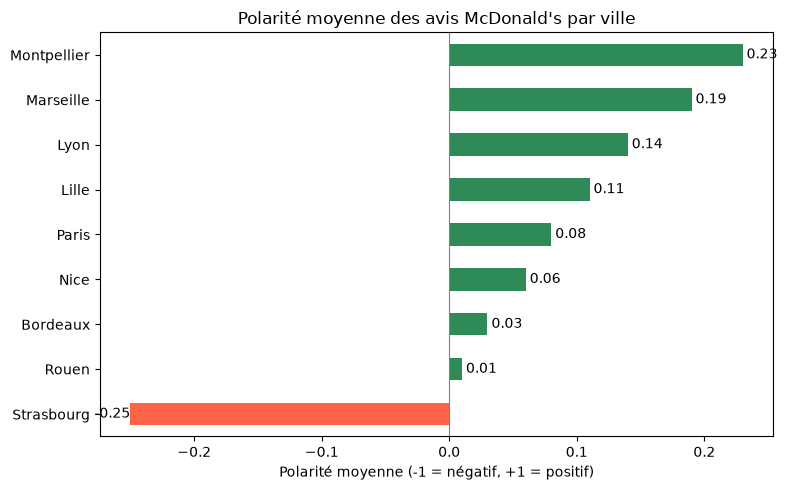

In [ ]:
# Graphique : polarité moyenne par ville (rouge = négatif, vert = positif)
import matplotlib.pyplot as plt

polarite_ville = df.groupby("ville")["polarite"].mean().sort_values().round(2)

couleurs = ["tomato" if p < 0 else "seagreen" for p in polarite_ville]

polarite_ville.plot(kind="barh", figsize=(8, 5), color=couleurs)
plt.axvline(0, color="grey", linewidth=0.8)
plt.title("Polarité moyenne des avis McDonald's par ville")
plt.xlabel("Polarité moyenne (-1 = négatif, +1 = positif)")
plt.ylabel("")

# Affiche la valeur au bout de chaque barre
for i, valeur in enumerate(polarite_ville):
    plt.text(valeur, i, f" {valeur}", va="center", ha="left" if valeur >= 0 else "right")

plt.tight_layout()
plt.show()

🔎 **Interprétation :**
- Toutes les villes ont une polarité **proche de 0** (entre -0,25 et +0,23) : le ton des avis est globalement **neutre à légèrement positif**, alors que la note moyenne est faible (2,7/5).
- Ce décalage est classique : les clients mélangent compliments et critiques (« le personnel est sympa **mais** 20 minutes d'attente »), ce qui « neutralise » la polarité. Les outils comme TextBlob détectent aussi mal l'ironie.
- **Strasbourg** est la seule ville négative (-0,25) mais ne repose que sur **un seul avis** ; **Montpellier** (+0,23) également.
- Sur les villes les mieux représentées, **Paris (0,08)** et **Nice (0,06)** sont à peine positives.

### 4.2 Sentiment par thème
On découpe chaque avis en **phrases**, puis on repère celles qui parlent de :
- **service** (accueil, attente, personnel, caisse…)
- **plats** (burger, frites, goût, qualité…)
- **livraison** (livreur, Uber Eats, Deliveroo…)

On calcule ensuite la polarité de ces phrases uniquement. Les mots-clés sont en français **et** en anglais car une partie des avis est rédigée en anglais.

In [ ]:
# Mots-clés permettant de reconnaître chaque thème (séparés par "|" = "ou")
mots = {
    "service": "service|accueil|attente|personnel|caisse|impoli|staff|wait|rude",
    "plats": "burger|frites|nuggets|froid|goût|qualité|fries|cold|taste|food",
    "livraison": "livraison|livreur|uber eats|deliveroo|mcdelivery|delivery|driver",
}

# Pour chaque phrase qui parle d'un thème, on calcule sa polarité
lignes = []
for _, row in df.dropna(subset=["avis"]).iterrows():
    for phrase in TextBlob(row["avis"]).sentences:
        texte_phrase = str(phrase).lower()
        for theme, liste in mots.items():
            if re.search(liste, texte_phrase):
                lignes.append({"ville": row["ville"], "theme": theme,
                               "polarite": sentiment(str(phrase))})

# Polarité moyenne par ville et par thème
df_themes = pd.DataFrame(lignes)
df_themes.groupby(["ville", "theme"])["polarite"].mean().unstack().round(2)

theme,plats,service
ville,,
Bordeaux,0.08,-0.10
Lille,-0.04,-0.14
Lyon,0.18,0.35
Marseille,0.32,0.19
Montpellier,0.23,NaN
Nice,-0.01,0.02
Paris,0.03,-0.02
Rouen,-0.50,0.20
Strasbourg,NaN,-0.30


🔎 **Interprétation :**
- La colonne **livraison** n'apparaît pas : **aucun avis ne parle de livraison**. Les avis Yelp portent sur l'expérience **en restaurant**.
- À **Paris** et **Nice** (les villes fiables), les phrases sur le service et les plats sont **neutres** (entre -0,02 et +0,03).
- Le **service** est jugé négativement à **Bordeaux, Lille, Strasbourg** ; les **plats** très négativement à **Rouen** (-0,50) — à relativiser vu le faible nombre d'avis.

### 4.3 Subjectivité
La **subjectivité** va de **0** (avis factuel : « j'ai commandé un menu ») à **1** (avis d'opinion : « c'est horrible »).

In [20]:
def subjectivite(texte):
    """Subjectivité du texte entre 0 (factuel) et 1 (opinion personnelle)."""
    if pd.isna(texte):
        return None
    if langue(texte) == "fr":
        return TextBlob(texte, pos_tagger=PatternTagger(), analyzer=PatternAnalyzer()).sentiment[1]
    return TextBlob(texte).sentiment.subjectivity

df["subjectivite"] = df["avis"].apply(subjectivite)

subjectivite_ville = df.groupby("ville")["subjectivite"].mean().sort_values().round(2)
subjectivite_ville

ville
Lille          0.39
Bordeaux       0.41
Montpellier    0.51
Paris          0.54
Marseille      0.55
Lyon           0.55
Rouen          0.56
Strasbourg     0.57
Nice           0.60
Name: subjectivite, dtype: float64

🔎 **Interprétation :** la subjectivité moyenne tourne autour de **0,4 à 0,6** : les avis mêlent **faits** (temps d'attente, commande) et **ressentis**. Ce sont donc des avis plutôt **argumentés**, pas seulement des réactions émotionnelles.

### 4.4 Nuages de mots
Les mots les plus fréquents de chaque ville (plus le mot est gros, plus il revient souvent). Les mots trop courants (« le », « et », « mcdonald »…) sont retirés.

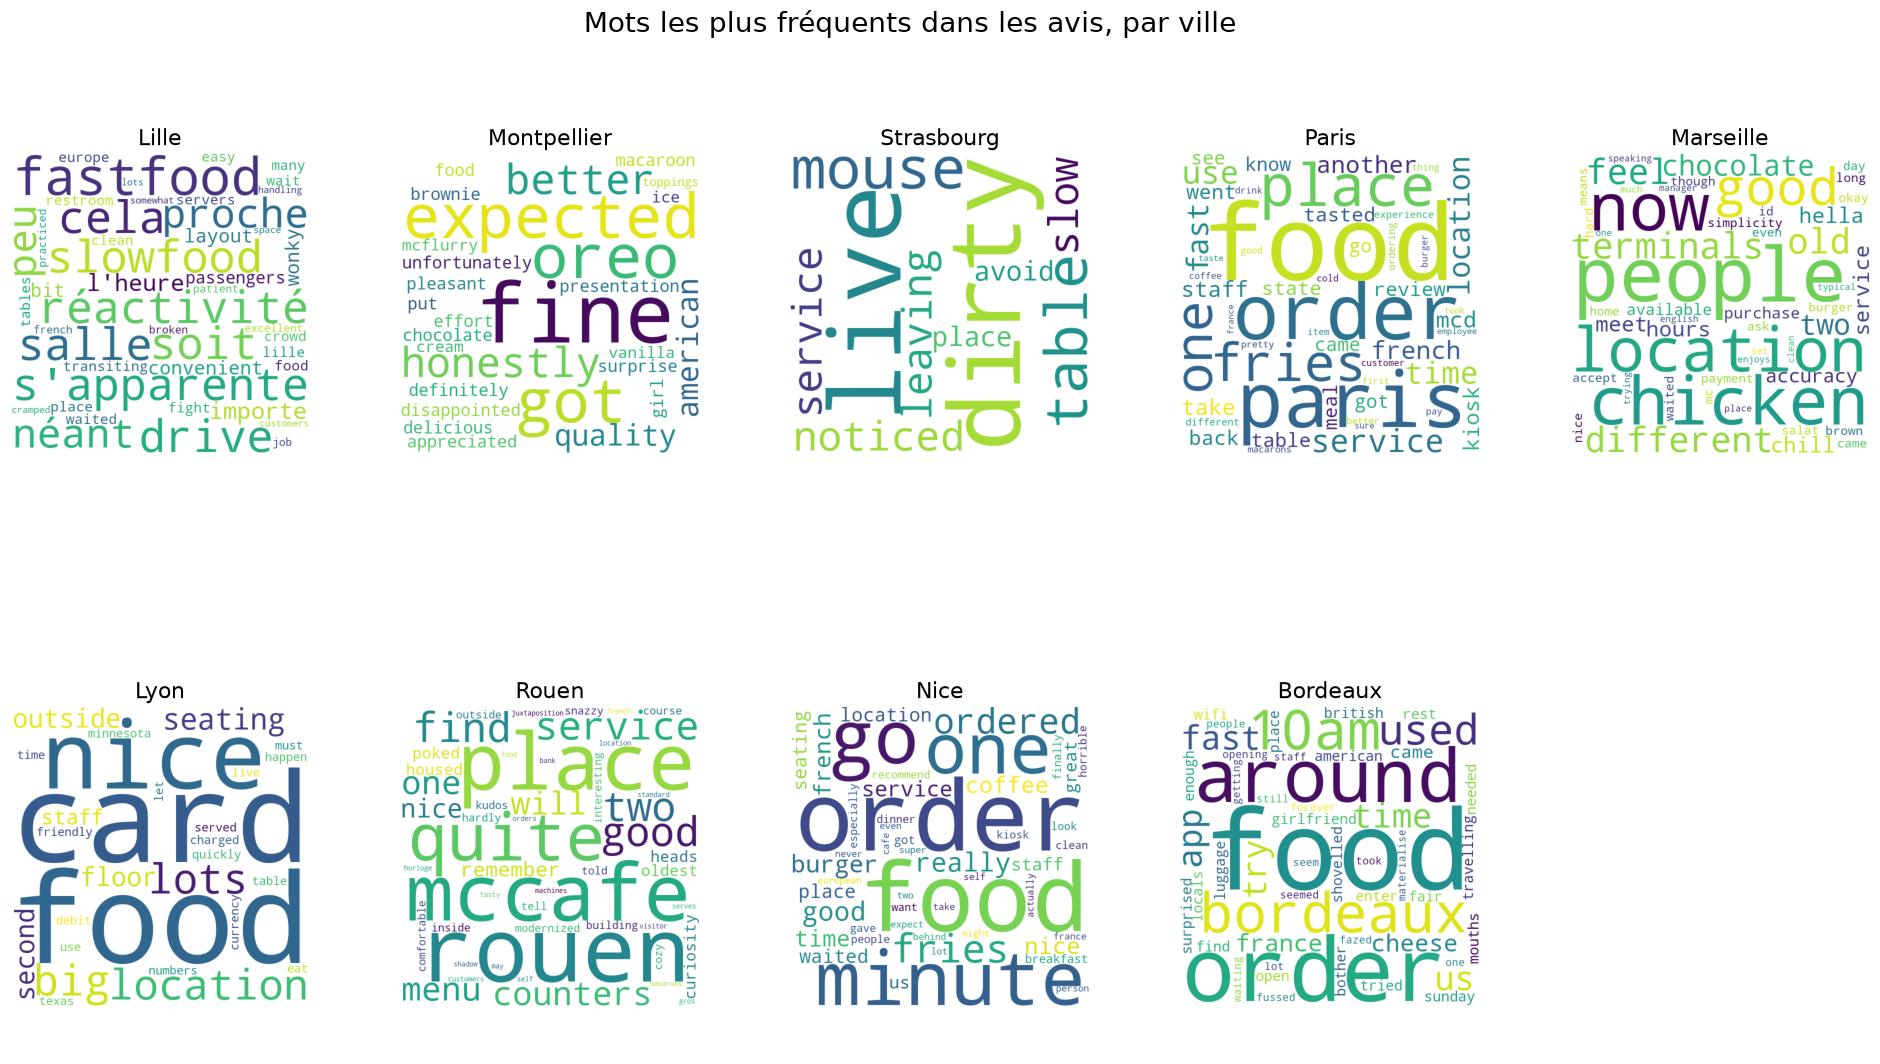

In [34]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

# Mots vides à ignorer (anglais par défaut + français + nom de l'enseigne)
mots_a_ignorer = set(STOPWORDS) | {
    "le", "la", "les", "un", "une", "des", "du", "de", "et", "en", "est", "pas", "que", "qui",
    "il", "elle", "on", "je", "j", "nous", "vous", "ils", "ce", "ça", "c", "a", "à", "au", "aux",
    "pour", "par", "sur", "avec", "dans", "mais", "ou", "très", "plus", "tout", "été", "fait",
    "mcdonald", "mcdonalds", "mcdo", "macdo", "restaurant",
}

villes_liste = df["ville"].dropna().unique()

fig, axes = plt.subplots(2, 5, figsize=(24, 12))

for ax, ville in zip(axes.flat, villes_liste):
    texte = " ".join(df[df["ville"] == ville]["avis"].dropna()).lower()
    if texte.strip() == "":
        ax.set_title(ville + " (aucun avis)")
        ax.axis("off")
        continue
    nuage = WordCloud(width=600, height=600, background_color="white",
                      stopwords=mots_a_ignorer, max_words=50).generate(texte)
    ax.imshow(nuage)
    ax.set_title(ville, fontsize=16)
    ax.axis("off")

# On masque les cases vides de la grille
for ax in axes.flat[len(villes_liste):]:
    ax.axis("off")

plt.suptitle("Mots les plus fréquents dans les avis, par ville", fontsize=20)
plt.subplots_adjust(wspace=0.3, hspace=0.4, top=0.9)
plt.show()

🔎 **Interprétation :** les nuages font ressortir le vocabulaire de l'**expérience en restaurant** (commande, attente, service, frites, burger…). Pour les villes avec peu d'avis, le nuage reflète surtout le contenu d'un ou deux avis.

### 4.5 Note moyenne par ville
On repère chaque thème dans l'avis **entier** (1 = l'avis en parle, 0 = non) pour pouvoir croiser les thèmes avec la note en étoiles.

In [ ]:
# Texte en minuscules (avis vides remplacés par du texte vide)
texte = df["avis"].fillna("").str.lower()

# 1 si l'avis contient un mot-clé du thème, 0 sinon
df["service"] = texte.str.contains("service|accueil|attente|personnel|caisse|impoli|staff|wait|rude").astype(int)
df["plats"] = texte.str.contains("burger|frites|nuggets|froid|goût|qualité|fries|cold|taste|food").astype(int)
df["livraison"] = texte.str.contains("livraison|livreur|uber eats|deliveroo|mcdelivery|delivery|driver").astype(int)

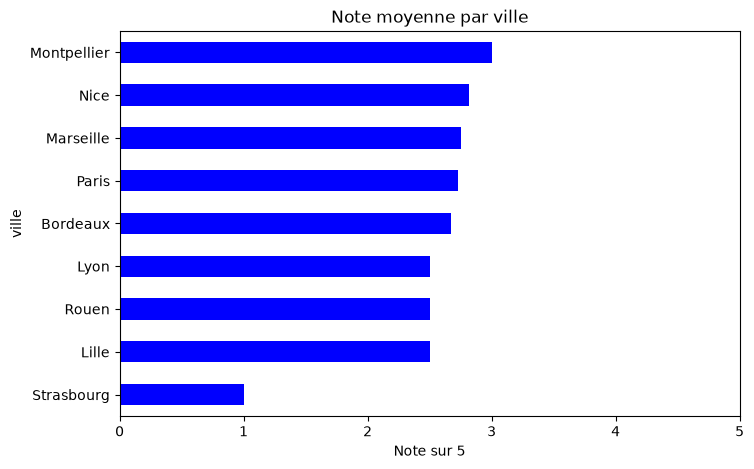

In [27]:
# Note moyenne par ville : où se trouve le problème ?
note_ville = df.groupby("ville")["note"].mean().sort_values().round(2)

note_ville.plot(kind="barh", figsize=(8, 5), color="blue")
plt.title("Note moyenne par ville")
plt.xlabel("Note sur 5")
plt.xlim(0, 5)
plt.show()

🔎 **Interprétation :** **aucune ville ne dépasse 3/5**. Les notes sont très proches (2,5 à 3), sauf Strasbourg (1/5, un seul avis). L'insatisfaction est donc **générale** et ne semble pas liée à une ville en particulier.

### 4.6 Note moyenne par thème

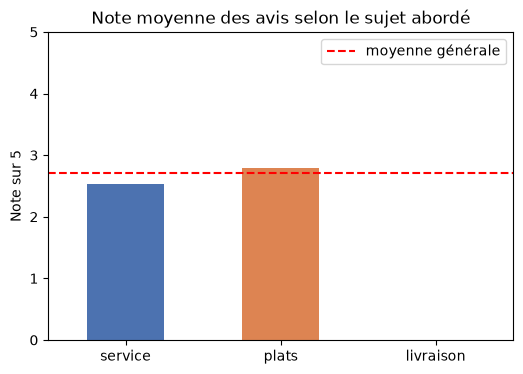

In [28]:
# Note moyenne des avis selon le thème abordé : quel sujet fait baisser la note ?
note_theme = pd.Series({
    "service": df[df["service"] == 1]["note"].mean(),
    "plats": df[df["plats"] == 1]["note"].mean(),
    "livraison": df[df["livraison"] == 1]["note"].mean(),
}).round(2)

note_theme.plot(kind="bar", figsize=(6, 4), rot=0, color=["#4c72b0", "#dd8452", "#55a868"])
plt.axhline(df["note"].mean(), color="red", linestyle="--", label="moyenne générale")
plt.title("Note moyenne des avis selon le sujet abordé")
plt.ylabel("Note sur 5")
plt.ylim(0, 5)
plt.legend()
plt.show()

🔎 **Interprétation :**
- Les avis qui parlent du **service** (43 avis) ont une note moyenne de **2,53**, **sous la moyenne générale** (2,71).
- Ceux qui parlent des **plats** (63 avis) sont à **2,79**, légèrement au-dessus.
- ➡️ **Le service est le principal facteur d'insatisfaction** : quand un client évoque l'accueil ou l'attente, c'est le plus souvent pour s'en plaindre.

### 4.7 Note par ville et par thème

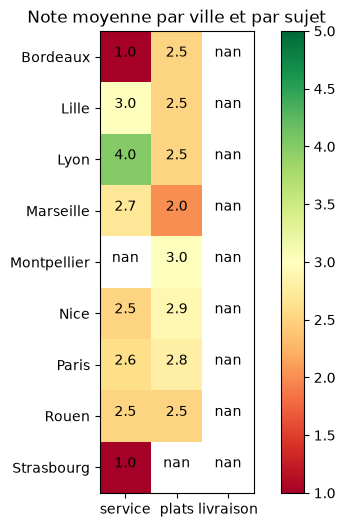

In [29]:
# Carte de chaleur : quel problème, dans quelle ville ? (rouge = mauvaise note, vert = bonne note)
tableau_notes = pd.DataFrame({
    "service": df[df["service"] == 1].groupby("ville")["note"].mean(),
    "plats": df[df["plats"] == 1].groupby("ville")["note"].mean(),
    "livraison": df[df["livraison"] == 1].groupby("ville")["note"].mean(),
}).round(1)

plt.figure(figsize=(7, 6))
plt.imshow(tableau_notes, cmap="RdYlGn", vmin=1, vmax=5)
plt.colorbar()
plt.xticks(range(3), tableau_notes.columns)
plt.yticks(range(len(tableau_notes)), tableau_notes.index)
for i in range(len(tableau_notes)):
    for j in range(3):
        plt.text(j, i, tableau_notes.iloc[i, j], ha="center")
plt.title("Note moyenne par ville et par sujet")
plt.show()

🔎 **Interprétation :** la carte est majoritairement **orange** (notes entre 2 et 3). Le **service** est le point noir à **Bordeaux** et **Strasbourg** (1/5), alors que **Lyon** s'en sort bien sur ce thème (4/5). La colonne livraison est vide (`nan`) faute d'avis sur ce sujet.

### 4.8 De quoi parlent les avis négatifs ?

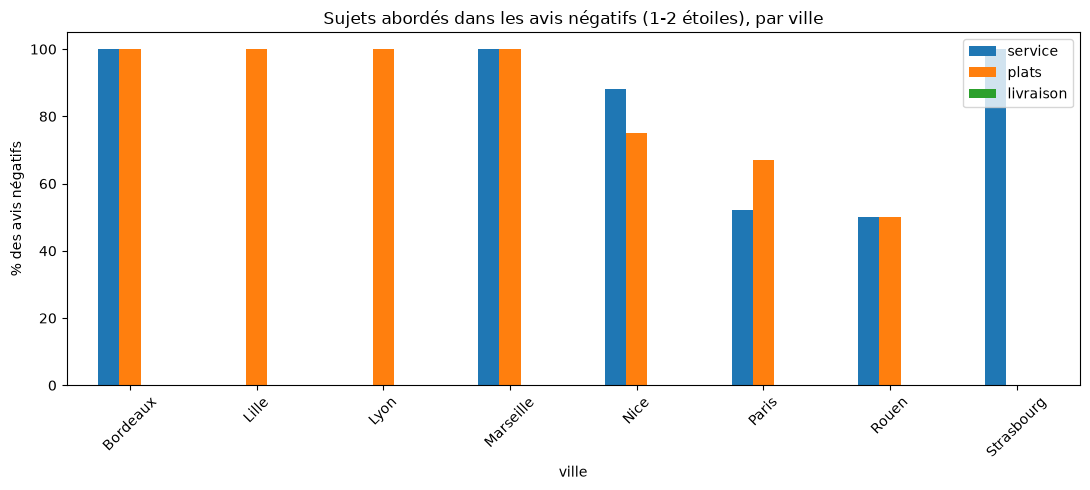

In [30]:
# Part de chaque thème dans les avis négatifs (1 ou 2 étoiles), par ville
negatifs = df[df["note"] <= 2]
plaintes = (negatifs.groupby("ville")[["service", "plats", "livraison"]].mean() * 100).round(0)

plaintes.plot(kind="bar", figsize=(11, 5), rot=45)
plt.title("Sujets abordés dans les avis négatifs (1-2 étoiles), par ville")
plt.ylabel("% des avis négatifs")
plt.tight_layout()
plt.show()

🔎 **Interprétation :** les avis négatifs parlent presque toujours **à la fois du service et des plats** (souvent 100 % dans les petites villes).
À **Nice**, 88 % des avis négatifs mentionnent le **service** ; à **Paris**, ce sont plutôt les **plats** (67 %) devant le service (52 %).

### 4.9 Répartition des étoiles par ville

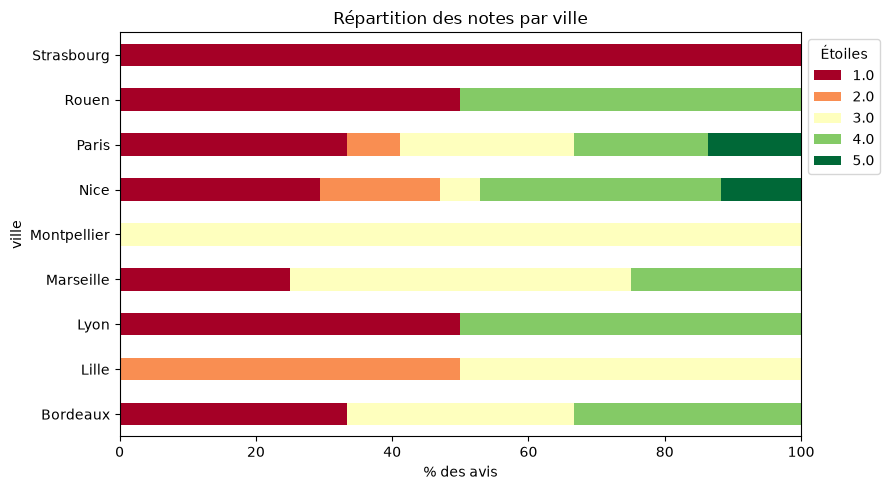

In [31]:
# Répartition des notes (en %) : clients très déçus ou juste moyennement satisfaits ?
repartition = pd.crosstab(df["ville"], df["note"], normalize="index") * 100

repartition.plot(kind="barh", stacked=True, figsize=(9, 5), cmap="RdYlGn")
plt.title("Répartition des notes par ville")
plt.xlabel("% des avis")
plt.legend(title="Étoiles", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

🔎 **Interprétation :** le **rouge foncé (1 étoile)** est présent presque partout et représente environ **un tiers des avis à Paris et à Nice**. Les notes de 5 étoiles sont rares (uniquement à Paris et Nice).
Les clients sont donc soit **très déçus**, soit **moyennement satisfaits** (3–4 ★) : l'enthousiasme est rare.

### 4.10 Évolution dans le temps

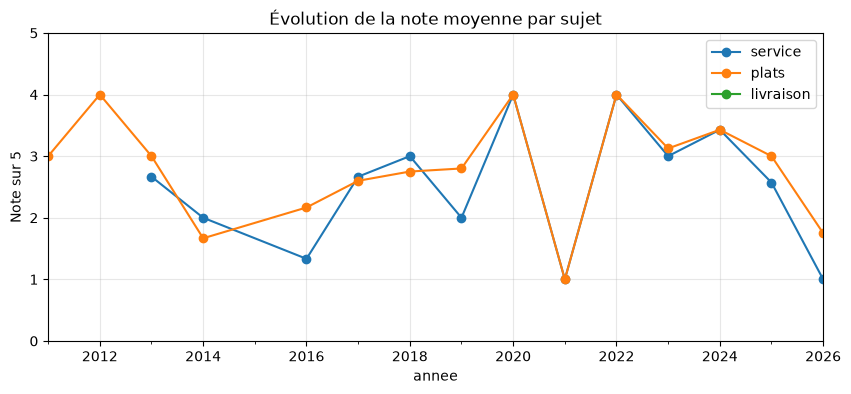

In [33]:
# Évolution de la note moyenne par thème et par année : quel problème s'aggrave ?
df["annee"] = pd.to_datetime(df["date"]).dt.to_period("Y")

evolution = pd.DataFrame({
    "service": df[df["service"] == 1].groupby("annee")["note"].mean(),
    "plats": df[df["plats"] == 1].groupby("annee")["note"].mean(),
    "livraison": df[df["livraison"] == 1].groupby("annee")["note"].mean(),
})

evolution.plot(figsize=(10, 4), marker="o")
plt.title("Évolution de la note moyenne par sujet")
plt.ylabel("Note sur 5")
plt.ylim(0, 5)
plt.grid(alpha=0.3)
plt.show()

🔎 **Interprétation :**
- Les avis couvrent **2010 à 2026**, avec la majorité depuis **2023** (38 avis sur 85).
- La courbe est très « en dents de scie » car certaines années n'ont que 1 à 3 avis (ex. le creux à 1/5 en 2021).
- Pas d'amélioration nette : la note moyenne est de **2,68 avant 2020** et **2,73 depuis 2020**.
- En **2025–2026**, la note des avis sur le **service** chute (de 3,4 en 2024 à 1 en 2026), un signal à surveiller avec davantage de données.

## 5. Conclusion

### Ce qu'il faut retenir
| # | Constat |
|---|---|
| 1 | **Satisfaction faible** : note moyenne de **2,7/5**, un tiers des avis à **1 étoile**. |
| 2 | **Problème général**, pas local : aucune ville ne dépasse 3/5. |
| 3 | **Le service est le premier irritant** : les avis qui en parlent ont la note la plus basse (2,5/5). |
| 4 | **Le texte est plus nuancé que la note** : polarité proche de 0, les clients mélangent points positifs et négatifs. |
| 5 | **La livraison n'apparaît pas** : Yelp reflète l'expérience en restaurant. |

### Limites
- **Petit échantillon** : 85 avis seulement, dont 60 % à Paris → les comparaisons entre villes sont fragiles.
- **Biais de sélection** : les clients mécontents laissent plus volontiers un avis.
- **Analyse de sentiment simple** : TextBlob se base sur un dictionnaire de mots ; il comprend mal l'ironie et les phrases mixtes.
- **Thèmes par mots-clés** : un avis peut être mal classé (ex. « food » dans « fast-food »).
- **Zone de recherche ≠ commune** : Yelp inclut des restaurants des communes voisines.

### Pistes d'amélioration
- Collecter plus d'avis (plus de villes, autres plateformes comme Google Maps).
- Utiliser un modèle de sentiment plus récent (ex. CamemBERT pour le français).
- Comparer avec d'autres enseignes de restauration rapide.